# 061 — svc rbf afinacao

Pesquisa curta de C/gamma em RBF; controlo C=1/gamma=scale.

**Estado: executado pelo runner; outputs guardados.**

Seleção dentro do treino de desenvolvimento (8.769 linhas), com os mesmos três folds. Validação fixa: 2.193 linhas, já observada anteriormente. Pré-processamento ajustado dentro de cada treino. Sem submissão automática.

061 resultado completo reutilizado após verificar o contexto.
Estado: procedimento concluído; resultados guardados com contexto verificado.
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração original (s): 1824.5540978339995
Notas: Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.
Selecionado: C_10.0_gamma_0.01
Configuração: {'family': 'svc', 'kernel': 'rbf', 'C': 10.0, 'gamma': 0.01, 'degree': 3, 'coef0': 0.0, 'class_weight': None, 'strategy': 'ovo', 'svd': 0}
Diferenças emparelhadas: {'differences': [0.03415434125403438, 0.03266121529339, 0.0365575635658284], 'mean': 0.03445770670441759, 'std': 0.0019658090986660126}
Escalões: controlo
Diagnósticos de ajuste: {'seconds': 127.58180179199553, 'warnings': [], 'sup

,configuração,Macro F1 CV,DP,folds
0,controlo_rbf,0.407543,0.006565,"[0.41511729596489455, 0.40402210716606396, 0.4..."
1,C_0.1_gamma_scale,0.142776,0.010602,"[0.1523826820844702, 0.1445447329254341, 0.131..."
2,C_10.0_gamma_scale,0.438178,0.006885,"[0.4453222737573898, 0.4315852388573825, 0.437..."
3,C_1.0_gamma_0.001,0.307431,0.004922,"[0.31079200564222775, 0.3097189026451041, 0.30..."
4,C_1.0_gamma_0.01,0.412696,0.011521,"[0.4243297020363729, 0.41246846644098156, 0.40..."
5,C_10.0_gamma_0.001,0.436375,0.004874,"[0.44160949034521324, 0.4319685470259664, 0.43..."
6,C_10.0_gamma_0.01,0.442001,0.006517,"[0.44927163721892893, 0.43668332245945396, 0.4..."


,modelo,parcela,Macro F1,accuracy
0,controlo,train,0.674871,0.700422
1,controlo,validation,0.398409,0.431373
2,selecionado,train,1.000000,1.000000
3,selecionado,validation,0.426192,0.432741


,classe,precision,recall,F1,support
0,0,0.738095,0.756098,0.746988,41
1,1,0.000000,0.000000,0.000000,34
2,2,0.500000,0.600000,0.545455,80
3,3,0.294118,0.200000,0.238095,75
4,4,0.333333,0.144444,0.201550,90
5,5,0.294964,0.317829,0.305970,129
6,6,0.332031,0.494186,0.397196,172
7,7,0.371951,0.352601,0.362018,173
8,8,0.595745,0.618785,0.607046,181
9,9,0.603687,0.645320,0.623810,203


,classe,precision,recall,F1,support
0,0,0.769231,0.731707,0.750000,41
1,1,0.473684,0.264706,0.339623,34
2,2,0.505882,0.537500,0.521212,80
3,3,0.306452,0.253333,0.277372,75
4,4,0.238095,0.222222,0.229885,90
5,5,0.295302,0.341085,0.316547,129
6,6,0.315789,0.348837,0.331492,172
7,7,0.364780,0.335260,0.349398,173
8,8,0.571429,0.596685,0.583784,181
9,9,0.589372,0.600985,0.595122,203


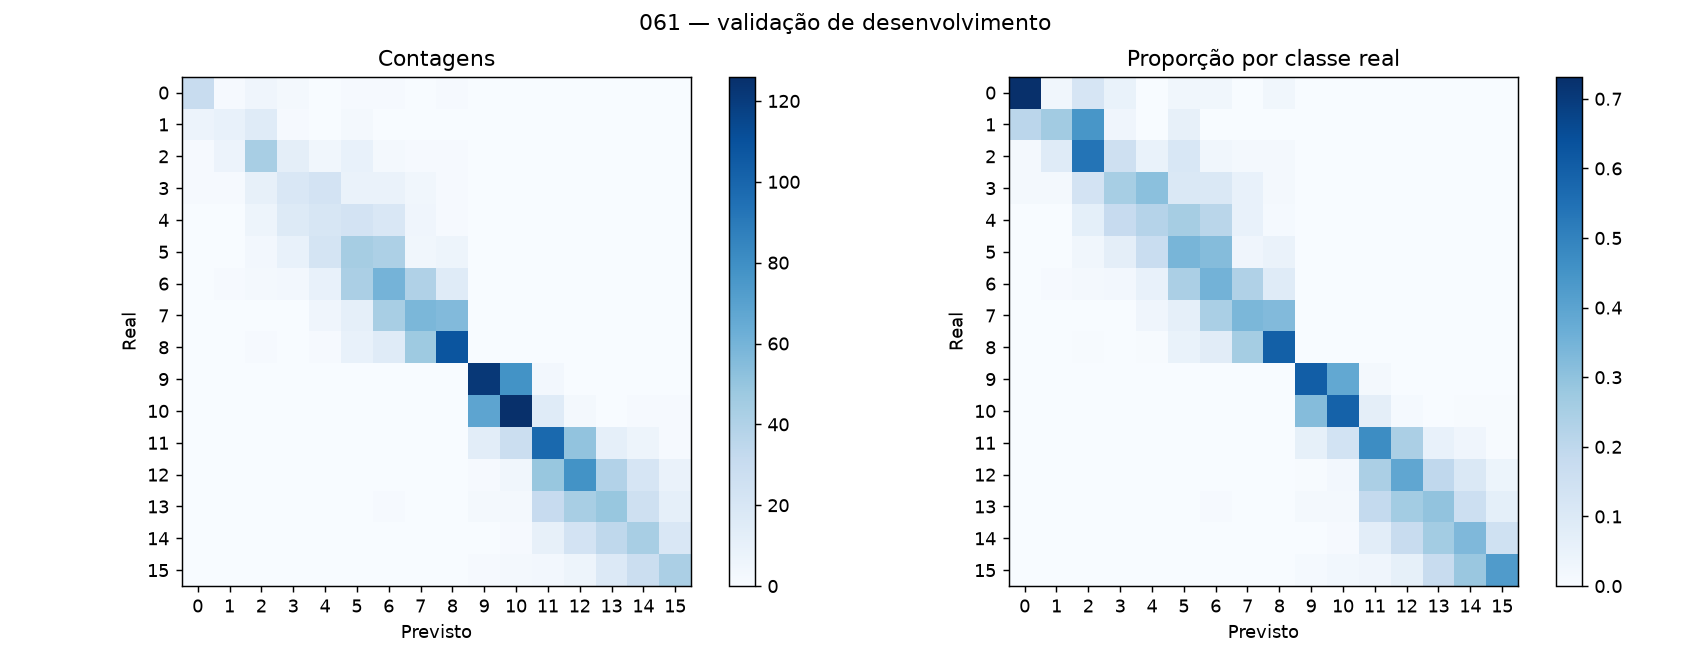

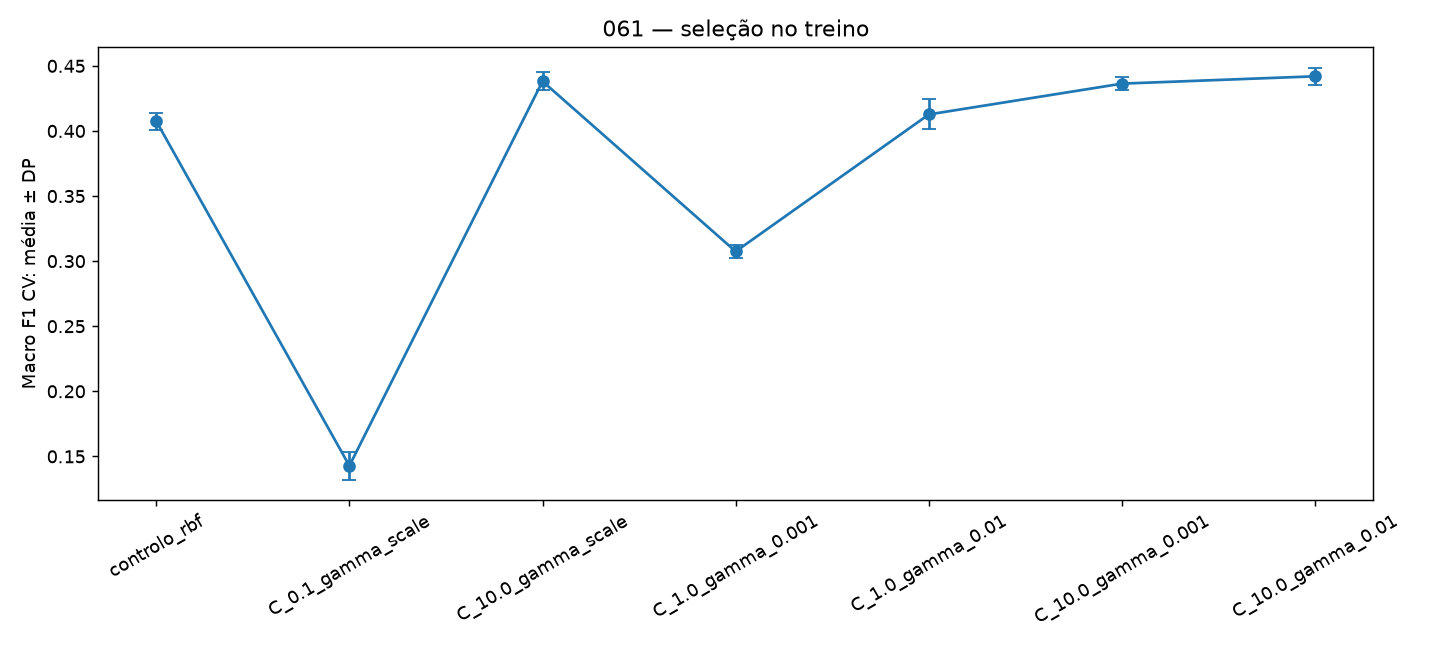

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p/'src/experiments_059_075.py').is_file())
sys.path.insert(0, str(root))
from src.experiments_059_075 import run_experiment
result = run_experiment('061')
print('Estado: procedimento concluído; resultados guardados com contexto verificado.')
print('Versões:', result['context']['base']['versions'])
print('Duração original (s):', result['seconds'])
print('Notas:', result.get('note', ''))
if result.get('candidates'):
    display(pd.DataFrame([{'configuração':r['label'],'Macro F1 CV':r['mean'],'DP':r['std'],'folds':r.get('folds',r.get('scores'))} for r in result['candidates']]))
if result.get('selected'):
    print('Selecionado:', result['selected']['label'])
    print('Configuração:', result['selected']['spec'])
if result.get('paired_cv'):
    print('Diferenças emparelhadas:', result['paired_cv'])
if result.get('fixed'):
    display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':groups[part]['macro_f1'],'accuracy':groups[part]['accuracy']} for name,groups in result['fixed'].items() for part in ['train','validation']]))
    for name, groups in result['fixed'].items():
        print('Escalões:', name)
        display(pd.DataFrame(groups['validation']['per_class']))
        print('Diagnósticos de ajuste:', groups.get('diagnostics'))
        print('MAE em códigos de escalão (não anos):', groups.get('mae_in_class_codes'))
        if 'log_loss' in groups: print('Log loss:',groups['log_loss'])
if result.get('metrics_oof'):
    print('Métricas OOF de desenvolvimento:', result['metrics_oof']['macro_f1'], result['metrics_oof']['accuracy'])
    display(pd.DataFrame(result['metrics_oof']['per_class']))
if 'selected_cases' in result:
    print('Perfis sinalizados:', result['flagged'], '/', result['total'])
    display(pd.DataFrame(result['selected_cases']))
    display(pd.DataFrame(result['by_class']))
if 'categorical_profiles' in result:
    table = pd.DataFrame(result['categorical_profiles'])
    display(table[table.variable.isin(['HATLEVEL','MAINSTAT','HHINCOME','HS1','HS2'])])
    display(pd.DataFrame(result['numeric_profiles']))
    display(pd.DataFrame(result['chronic_diseases']))
for file in sorted((root/'reports').glob('experiencia_061_*.png')):
    display(Image(filename=str(file)))
print('CSV Kaggle:', result.get('submission'))
print('Pontuação Kaggle:', result['kaggle_score'])


## Conclusões locais

- Selecionado internamente: `C_10.0_gamma_0.01`.
- Macro F1 desenvolvimento: **0.4262**; accuracy: **0.4327**.
- Diferença face ao controlo contemporâneo: **+0.0278**.
- Diferença média nos mesmos folds: **+0.0345**, DP **0.0020**.
- CSV: `submissions/submission_061_svc_rbf_afinacao.csv`. Motivo se não criado: —.

Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.

**Decisão:** preencher depois da revisão; não inferir melhoria pública de uma pequena diferença local.

## Registo manual

- Data:
- CSV submetido (se aplicável):
- Nota Kaggle:
- Conclusão:
- Melhorias a experimentar:

Esta célula e quaisquer notas pessoais não são substituídas pelo script.